# 03 — Machine Learning Modeling

**Personal Tabular Machine Learning Handbook**


## Learning objectives
- Distinguish regression and classification, learned parameters and chosen hyperparameters.
- Fit baselines, linear models, trees, forests, and a boosting example with reusable syntax.
- Compare on validation/CV, tune safely, and save a full inference pipeline.

**Project handoff:** This notebook uses the raw typed splits and unfitted transformer from 02. Primary regression selection uses validation MAE (lower is better). A separate built-in classification case teaches probabilities and thresholds.

**Before you run:** Run 02 first. Execute from the repository root. Never select a model by its test score. The final primary test evaluation belongs only in 04.

**How to use this notebook:** Read top to bottom the first time. Later, search for a `Technique:` heading or use the Quick Syntax Reference. Each code example is executable after its preceding setup cells. Outputs are included for revision.

## A. Machine Learning Fundamentals

**Supervised learning** learns an input-to-outcome relationship from labeled examples.

| Concept | Meaning | Example |
|---|---|---|
| Regression | Predict a numerical amount | Monthly sales in IDR million |
| Classification | Predict a category, often with probabilities | Malignant versus benign |
| Training | Learn from labeled training data | `.fit(X_train, y_train)` |
| Inference | Predict using the learned model | `.predict(new_stores)` |
| Parameter | Value learned during training | Linear coefficient or tree split |
| Hyperparameter | Setting chosen before fitting | Tree depth or forest size |
| Underfitting | Model misses important structure | Large training and validation errors |
| Overfitting | Model learns training-specific noise | Small training but much larger validation error |

**Bias–variance intuition:** A rigid model can miss the pattern (high bias); a very flexible model can change greatly with the sample (high variance). More complexity is useful only if it improves performance on new data. There is no universally best algorithm.

**Available at prediction time:** This project assumes spending and region are known before monthly sales are estimated. If recorded promotion spending is only available after the month closes, the task is an association model rather than a genuine advance forecast. Confirm timing before deployment.

In [1]:
from pathlib import Path
import importlib.util
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer

bundle = joblib.load("data/processed/regression_splits.joblib")
X_train, y_train = bundle["X_train"], bundle["y_train"]
X_validation, y_validation = bundle["X_validation"], bundle["y_validation"]
preprocessor = bundle["preprocessor_template"]
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
print("Loaded training and validation:", X_train.shape, X_validation.shape)

Loaded training and validation: (51, 2) (17, 2)


## B. Linear Regression

### Technique: LinearRegression: fitting and predicting

**What is it?** Linear regression learns coefficients for a weighted sum of features plus an intercept.

**Why do we use it?** It is a simple, interpretable starting model for a numerical target.

**When should we use it?** Use when an approximately additive linear relationship is a reasonable starting point; inspect errors and compare with alternatives.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [2]:
linear_pipeline = Pipeline([
    ("prepare", clone(preprocessor)),
    ("model", LinearRegression()),
])
linear_pipeline.fit(X_train, y_train)
linear_predictions = linear_pipeline.predict(X_validation)
print("First validation estimates:", linear_predictions[:5].round(2))
print("Validation MAE:", round(mean_absolute_error(y_validation, linear_predictions), 2))

First validation estimates: [187.3  289.89 290.6  164.23 209.66]
Validation MAE: 17.21


**Interpretation:** fit learns preprocessing statistics and coefficients from training only. predict applies the same preparation before estimating sales. MAE is the average absolute error in IDR million.

**Things to Remember:** For one feature: predicted sales = intercept + slope × spending. With region included, the equation adds a region indicator. These coefficients reflect association, not causal marketing returns. Unconstrained predictions can be negative on unfamiliar inputs.

### Technique: Slope, intercept, coefficient names, and predictions

**What is it?** Each coefficient multiplies one transformed feature; the intercept is the prediction when all transformed features are zero.

**Why do we use it?** Seeing names alongside weights prevents misinterpreting encoded/scaled inputs.

**When should we use it?** Use for understanding a fitted linear model and checking whether its behavior is plausible.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

numeric__promo_spend_million    64.701098
categorical__region_Sumatra     -0.057263
dtype: float64

Intercept: 254.18434682004255


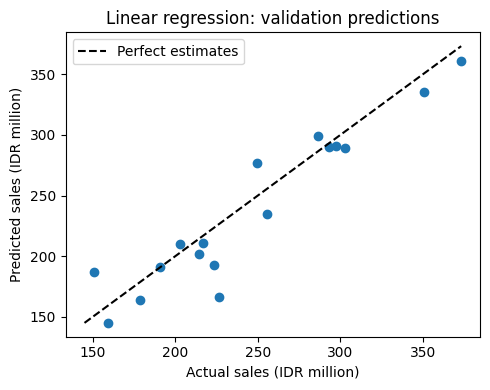

In [3]:
names = linear_pipeline.named_steps["prepare"].get_feature_names_out()
coefficients = pd.Series(linear_pipeline.named_steps["model"].coef_, index=names)
display(coefficients)
print("Intercept:", linear_pipeline.named_steps["model"].intercept_)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(y_validation, linear_predictions)
limits = [min(y_validation.min(), linear_predictions.min()), max(y_validation.max(), linear_predictions.max())]
ax.plot(limits, limits, "--", color="black", label="Perfect estimates")
ax.set(title="Linear regression: validation predictions", xlabel="Actual sales (IDR million)", ylabel="Predicted sales (IDR million)")
ax.legend(); fig.tight_layout(); plt.show()

**Interpretation:** Points near the diagonal are accurate estimates. The spending coefficient is per one training standard deviation because spending was scaled; the region indicator is relative to the dropped reference category.

**Things to Remember:** Do not interpret a scaled coefficient as per IDR 1 million without converting it back. Correlated predictors, omitted variables, and small samples can make coefficients unstable. Notebook 04 demonstrates conversion.

## C. Logistic Regression

This is a separate classification case. The built-in breast-cancer dataset contains measured cell characteristics; malignant is explicitly encoded as 1. We use it to teach syntax, not clinical practice. It does not change the NusantaraMart regression target.

In [4]:
cancer = load_breast_cancer(as_frame=True)
classification_X = cancer.data
classification_y = (cancer.target == 0).astype(int).rename("malignant")
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    classification_X, classification_y, test_size=0.20, stratify=classification_y, random_state=42
)
print("Classification training / held-out rows:", len(X_class_train), len(X_class_test))

Classification training / held-out rows: 455 114


### Technique: LogisticRegression, probabilities, and thresholds

**What is it?** Despite its name, logistic regression is a classifier. It converts a weighted feature score to a probability between 0 and 1.

**Why do we use it?** A probability lets you separate a risk estimate from the decision rule.

**When should we use it?** Use as an interpretable baseline for binary classification, usually with numeric feature scaling.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [5]:
logistic_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42)),
])
logistic_pipeline.fit(X_class_train, y_class_train)
positive_column = list(logistic_pipeline.classes_).index(1)
training_probabilities = logistic_pipeline.predict_proba(X_class_train.iloc[:5])[:, positive_column]
print("Training example probabilities:", training_probabilities.round(3))
print("Labels at 0.5:", (training_probabilities >= 0.5).astype(int))
print("Labels at 0.2:", (training_probabilities >= 0.2).astype(int))

Training example probabilities: [0.94  0.001 0.001 0.99  1.   ]
Labels at 0.5: [1 0 0 1 1]
Labels at 0.2: [1 0 0 1 1]


**Interpretation:** predict_proba returns one column per class in classes_ order. A lower threshold usually labels more observations positive, potentially improving recall at the cost of more false alarms. These are training examples, not evaluation scores.

**Things to Remember:** Choose thresholds on training/CV or validation using decision costs, never on the final holdout. A probability of 0.8 is not automatically calibrated; a separate calibration check is needed for risk decisions.

## D. Decision Trees

### Technique: DecisionTreeRegressor and tree depth

**What is it?** A tree asks a sequence of feature-threshold questions, then predicts an average target in each leaf.

**Why do we use it?** It captures nonlinear patterns and interactions without requiring a linear equation.

**When should we use it?** Use for explainable small rule structures, with depth/leaf constraints to limit overfitting.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

Tree validation MAE: 21.378408029878617


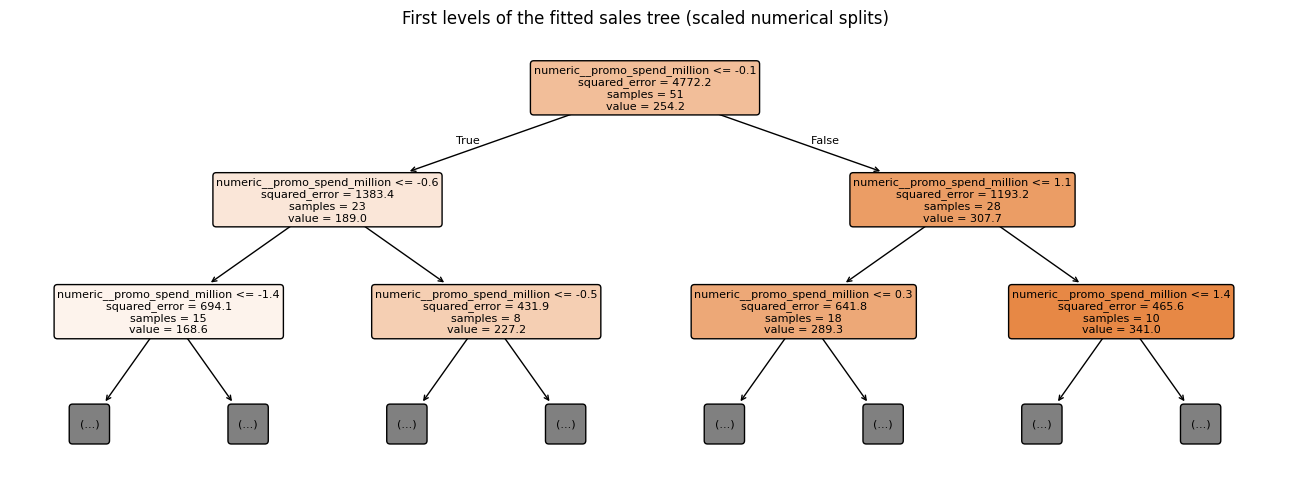

In [6]:
tree_pipeline = Pipeline([
    ("prepare", clone(preprocessor)),
    ("model", DecisionTreeRegressor(max_depth=3, min_samples_leaf=4, random_state=42)),
])
tree_pipeline.fit(X_train, y_train)
print("Tree validation MAE:", mean_absolute_error(y_validation, tree_pipeline.predict(X_validation)))
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(tree_pipeline.named_steps["model"], feature_names=tree_pipeline.named_steps["prepare"].get_feature_names_out(),
          filled=True, rounded=True, precision=1, ax=ax, max_depth=2, fontsize=8)
ax.set_title("First levels of the fitted sales tree (scaled numerical splits)")
fig.tight_layout(); plt.show()

**Interpretation:** Each box shows a rule, sample count, and leaf/node mean sales. A depth limit controls the number of successive questions. plot_tree max_depth limits only the display; estimator max_depth limits fitting.

**Things to Remember:** Trees can be unstable with small samples and overfit if unconstrained. Scaling is retained for workflow consistency but is not required for tree split quality. Tree predictions are piecewise constant and do not extrapolate trends beyond observed leaves.

## E. Random Forest

### Technique: RandomForestRegressor and ensemble learning

**What is it?** A random forest averages many trees trained with sampled rows and random feature subsets.

**Why do we use it?** Averaging can reduce the instability of an individual tree.

**When should we use it?** Use as a strong nonlinear tabular baseline when simple linear behavior may be insufficient.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [7]:
forest_pipeline = Pipeline([
    ("prepare", clone(preprocessor)),
    ("model", RandomForestRegressor(n_estimators=150, max_depth=4, min_samples_leaf=3,
                                     max_features=1.0, random_state=42, n_jobs=1)),
])
forest_pipeline.fit(X_train, y_train)
print("Forest validation MAE:", mean_absolute_error(y_validation, forest_pipeline.predict(X_validation)))
forest_names = forest_pipeline.named_steps["prepare"].get_feature_names_out()
display(pd.Series(forest_pipeline.named_steps["model"].feature_importances_, index=forest_names).sort_values(ascending=False))

Forest validation MAE: 23.240414451452697


numeric__promo_spend_million    0.993904
categorical__region_Sumatra     0.006096
dtype: float64

**Interpretation:** The model averages tree estimates; n_estimators controls tree count. Printed impurity importances describe how splits reduced training error across trees.

**Things to Remember:** More trees do not eliminate overfitting or weak data. Impurity importance is biased toward features offering many possible splits and can divide importance across correlated inputs. It is not evidence of causation.

## F. Gradient Boosting Introduction

Boosting builds trees sequentially, with later trees correcting remaining errors. The learning rate controls each new tree's contribution. Forests average varied trees; boosting improves a sequence of trees. Boosting can be powerful on tabular data but still needs careful validation.

### Technique: GradientBoostingRegressor: an offline core example

**What is it?** Scikit-learn provides a boosting implementation without optional dependencies.

**Why do we use it?** It lets us compare sequential trees with a forest in the same safe pipeline.

**When should we use it?** Use a modest number of shallow trees as a starting point, then tune if justified.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [8]:
boosting_pipeline = Pipeline([
    ("prepare", clone(preprocessor)),
    ("model", GradientBoostingRegressor(n_estimators=80, learning_rate=0.05, max_depth=2, random_state=42)),
])
boosting_pipeline.fit(X_train, y_train)
print("Boosting validation MAE:", mean_absolute_error(y_validation, boosting_pipeline.predict(X_validation)))

Boosting validation MAE: 23.104077437042854


**Interpretation:** The displayed MAE is validation evidence for this fixed configuration, not a universal ranking of algorithms.

**Things to Remember:** Depth, learning rate, and tree count interact. A more advanced package cannot compensate for leakage, tiny samples, or a poorly defined target.

### Optional packages: XGBoost, LightGBM, and CatBoost

| Package | General strength | Things to check |
|---|---|---|
| XGBoost | Regularized, flexible gradient-boosted trees; common competition baseline | Depth, learning rate, regularization, and validation strategy |
| LightGBM | Efficient histogram-based boosting, often fast on larger tables | Leaf growth/minimum leaf size; small datasets can overfit |
| CatBoost | Strong native categorical handling when configured with categorical columns | Input schema and category definitions; training cost |

The following **optional syntax examples** run only if a package is installed. They use the shared numeric preprocessing for consistency; CatBoost's native categorical pathway is a separate alternative, not used here. They are not included in core model selection. Do not install anything to finish this handbook.

In [9]:
optional_estimators = {}
if importlib.util.find_spec("xgboost") is not None:
    from xgboost import XGBRegressor
    optional_estimators["XGBoost"] = XGBRegressor(n_estimators=30, max_depth=2, learning_rate=0.05, random_state=42, n_jobs=1)
if importlib.util.find_spec("lightgbm") is not None:
    from lightgbm import LGBMRegressor
    optional_estimators["LightGBM"] = LGBMRegressor(n_estimators=30, max_depth=2, num_leaves=4, random_state=42, n_jobs=1, verbosity=-1)
if importlib.util.find_spec("catboost") is not None:
    from catboost import CatBoostRegressor
    optional_estimators["CatBoost"] = CatBoostRegressor(iterations=30, depth=2, learning_rate=0.05, random_seed=42, thread_count=1, verbose=False)
for name, estimator in optional_estimators.items():
    optional_pipeline = Pipeline([("prepare", clone(preprocessor)), ("model", estimator)])
    optional_pipeline.fit(X_train, y_train)
    print(name, "example validation predictions:", optional_pipeline.predict(X_validation.iloc[:3]).round(2))
if not optional_estimators:
    print("Optional packages not installed; core workflow is complete without them.")

XGBoost example validation predictions: [196.34 285.83 285.83]


## G. Model Training Workflow

Baseline → choose algorithm → fit training → predict validation → compare → save. A baseline establishes whether complexity adds value. Validation can become overused too: limit experiments and use CV rather than endlessly adapting to 17 validation rows.

### Technique: DummyRegressor baseline and a model comparison loop

**What is it?** A dummy regressor ignores inputs and predicts a training statistic.

**Why do we use it?** A sophisticated model must improve on a simple reference to justify its complexity.

**When should we use it?** For MAE, a training-median baseline is a natural choice; choose metrics based on decision costs.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [10]:
baseline_pipeline = Pipeline([("prepare", clone(preprocessor)), ("model", DummyRegressor(strategy="median"))])
candidate_templates = {"Median baseline": baseline_pipeline, "Linear regression": linear_pipeline,
                       "Decision tree": tree_pipeline, "Random forest": forest_pipeline, "Gradient boosting": boosting_pipeline}
fitted_candidates = {}
for name, template in candidate_templates.items():
    fitted_candidates[name] = clone(template).fit(X_train, y_train)
print("Fitted candidates:", list(fitted_candidates))

Fitted candidates: ['Median baseline', 'Linear regression', 'Decision tree', 'Random forest', 'Gradient boosting']


**Interpretation:** clone makes an unfitted copy, so each model learns its own training-only preprocessing. Fitting does not evaluate a model; the later comparison uses held-out validation.

**Things to Remember:** Keep baseline and candidate scores on exactly the same rows and metric. The baseline is a legitimate candidate if other models cannot beat it reliably.

## H. Hyperparameter Tuning

Cross-validation repeatedly fits on part of the training set and validates on the remaining fold. It estimates variability and supports selection without repeatedly touching the final test set. Preprocessing must be inside each fold's pipeline.

### Technique: KFold and GridSearchCV

**What is it?** Grid search tries every combination in a small specified hyperparameter grid.

**Why do we use it?** It provides a systematic alternative to guessing settings.

**When should we use it?** Use when the search space is small and the validation strategy matches deployment.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [11]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
tree_grid = {"model__max_depth": [2, 3, None], "model__min_samples_leaf": [2, 5]}
grid_search = GridSearchCV(clone(tree_pipeline), param_grid=tree_grid, cv=cv,
                           scoring="neg_mean_absolute_error", n_jobs=1, refit=True)
grid_search.fit(X_train, y_train)
print("Best tree settings:", grid_search.best_params_)
print("Best mean CV MAE:", -grid_search.best_score_)
fitted_candidates["Grid-tuned tree"] = grid_search.best_estimator_

Best tree settings: {'model__max_depth': 3, 'model__min_samples_leaf': 5}
Best mean CV MAE: 23.554150326797384


**Interpretation:** Six settings are evaluated over three folds. model__ names address the model step in the pipeline. Scikit-learn search maximizes scores, so it negates MAE; reverse the sign for readable error.

**Things to Remember:** A best CV score is a selection estimate, not a final unbiased test score. With 51 training stores, three-fold scores can vary greatly. Do not tune on the test set.

### Technique: RandomizedSearchCV

**What is it?** Randomized search samples a limited number of combinations instead of testing the full grid.

**Why do we use it?** It makes larger spaces affordable with a fixed trial budget.

**When should we use it?** Use when many hyperparameter combinations are possible; choose meaningful ranges first.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [12]:
forest_space = {"model__n_estimators": [80, 150], "model__max_depth": [2, 4, None],
                "model__min_samples_leaf": [2, 4]}
random_search = RandomizedSearchCV(clone(forest_pipeline), param_distributions=forest_space,
                                   n_iter=4, cv=cv, scoring="neg_mean_absolute_error", random_state=42, n_jobs=1)
random_search.fit(X_train, y_train)
print("Best forest settings:", random_search.best_params_)
print("Best mean CV MAE:", -random_search.best_score_)
fitted_candidates["Random-tuned forest"] = random_search.best_estimator_

Best forest settings: {'model__n_estimators': 80, 'model__min_samples_leaf': 2, 'model__max_depth': None}
Best mean CV MAE: 21.74076052365392


**Interpretation:** Only four combinations are sampled, each with its own fold-local preprocessing. The selected estimator is refitted on all training rows by default.

**Things to Remember:** Random search is not guaranteed to find the optimum. More trials increase cost and selection bias. Keep the final holdout untouched.

### Compare candidates on validation, then lock the choice

MAE in IDR million is the primary selection criterion here. We also retain RMSE and R² to understand error size and baseline-relative fit. If differences are small, prefer a simpler model and collect more evidence rather than treating a tiny score difference as definitive.

In [13]:
rows = []
for name, fitted in fitted_candidates.items():
    train_predictions = fitted.predict(X_train)
    val_predictions = fitted.predict(X_validation)
    rows.append({"model": name, "train_mae": mean_absolute_error(y_train, train_predictions),
                 "validation_mae": mean_absolute_error(y_validation, val_predictions),
                 "validation_rmse": root_mean_squared_error(y_validation, val_predictions),
                 "validation_r2": r2_score(y_validation, val_predictions)})
comparison = pd.DataFrame(rows).set_index("model").sort_values("validation_mae")
display(comparison.round(3))
selected_name = comparison.index[0]  # predetermined rule: smallest validation MAE
selected_training_pipeline = fitted_candidates[selected_name]
print("Locked primary model choice:", selected_name)

,train_mae,validation_mae,validation_rmse,validation_r2
model,,,,
Linear regression,18.780,17.208,22.250,0.872
Decision tree,15.766,21.378,24.774,0.841
Grid-tuned tree,16.871,22.028,25.655,0.830
Gradient boosting,14.132,23.104,26.633,0.817
Random forest,15.463,23.240,27.688,0.802
Random-tuned forest,14.078,25.013,29.230,0.779
Median baseline,59.845,57.147,65.904,-0.122


Locked primary model choice: Linear regression


**Interpretation:** Read the table to see which model actually won. A large train–validation error gap can indicate overfitting, but one small split is noisy. No model is declared best before these calculations run. The selection rule is fixed; do not revisit it after seeing test performance.

### Classification counterparts and training-only CV selection

DecisionTreeClassifier predicts class distributions in leaves. RandomForestClassifier averages probability estimates across trees. We compare a baseline and three classifiers by training-only stratified CV ROC-AUC; the classification holdout stays unopened until 04. ROC-AUC evaluates ranking, not a chosen operating threshold.

In [14]:
classification_templates = {
    "Dummy classifier": Pipeline([("scale", StandardScaler()), ("model", DummyClassifier(strategy="prior"))]),
    "Logistic regression": clone(logistic_pipeline),
    "Decision tree": Pipeline([("scale", StandardScaler()), ("model", DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42))]),
    "Random forest": Pipeline([("scale", StandardScaler()), ("model", RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=42, n_jobs=1))]),
}
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
classification_rows, classification_models = [], {}
for name, template in classification_templates.items():
    auc_scores = cross_val_score(template, X_class_train, y_class_train, cv=stratified_cv, scoring="roc_auc", n_jobs=1)
    classification_rows.append({"model": name, "cv_auc_mean": auc_scores.mean(), "cv_auc_std": auc_scores.std()})
    classification_models[name] = clone(template).fit(X_class_train, y_class_train)
classification_comparison = pd.DataFrame(classification_rows).set_index("model").sort_values("cv_auc_mean", ascending=False)
display(classification_comparison.round(4))
classification_choice = classification_comparison.index[0]
print("Locked classification choice:", classification_choice, "; threshold = 0.5")

,cv_auc_mean,cv_auc_std
model,,
Logistic regression,0.9958,0.0047
Random forest,0.9878,0.0075
Decision tree,0.9418,0.0318
Dummy classifier,0.5000,0.0000


Locked classification choice: Logistic regression ; threshold = 0.5


**Interpretation:** The mean AUC compares ranking performance; fold standard deviation indicates variability, not a confidence interval. The selected classifier and threshold are now fixed. Neither selection uses held-out labels. Accuracy, precision, and recall will be interpreted in 04.

## I. Saving and Loading Models

After selection, refit the primary model on training plus validation to use all development data. This final pipeline will have updated preprocessing statistics and fitted model parameters. Keep the earlier training-only candidates for honest validation interpretation; do not recompute validation scores using the final refitted model.

### Technique: Joblib serialization of a full fitted pipeline

**What is it?** Serialization saves Python objects so fitted preprocessing and the model can be restored together.

**Why do we use it?** Inference must apply the same schema and transformations used during training.

**When should we use it?** Save a full pipeline and a model metadata file when a model choice is locked.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [15]:
X_development = pd.concat([X_train, X_validation])
y_development = pd.concat([y_train, y_validation])
final_pipeline = clone(selected_training_pipeline).fit(X_development, y_development)
final_baseline = clone(baseline_pipeline).fit(X_development, y_development)
joblib.dump(final_pipeline, models_dir / "final_sales_pipeline.joblib")
joblib.dump(final_baseline, models_dir / "final_sales_baseline.joblib")
joblib.dump(fitted_candidates, models_dir / "training_candidates.joblib")
comparison.to_csv(models_dir / "regression_validation_comparison.csv")
restored = joblib.load(models_dir / "final_sales_pipeline.joblib")
new_store = pd.DataFrame({"promo_spend_million": [25.0], "region": ["Java"]})
print("Saved pipeline estimate for the example store:", restored.predict(new_store).round(2))

Saved pipeline estimate for the example store: [293.85]


**Interpretation:** The saved pipeline accepts raw feature columns and performs its own preparation. The example is inference, not evaluation; actual sales for this new row are unknown.

**Things to Remember:** Load only trusted Joblib/pickle files: they can execute code. Record versions and retrain if versions change. Do not save only coefficients or a standalone scaler and expect automatic compatibility.

In [16]:
classification_bundle = {"X_train": X_class_train, "y_train": y_class_train,
                         "X_test": X_class_test, "y_test": y_class_test,
                         "models": classification_models, "comparison": classification_comparison,
                         "selected_name": classification_choice, "threshold": 0.5, "positive_label": 1}
joblib.dump(classification_bundle, models_dir / "classification_case.joblib")
metadata = {"selected_model": selected_name, "selection_rule": "lowest validation MAE",
            "feature_order": bundle["feature_order"], "target": bundle["target"], "target_units": "IDR million",
            "refit_rows": len(X_development), "random_state": 42,
            "versions": {"python": platform.python_version(), "numpy": np.__version__,
                         "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "joblib": joblib.__version__}}
(models_dir / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved metadata and the separate classification case. No test scores computed.")

Saved metadata and the separate classification case. No test scores computed.


## Summary and Quick Syntax Reference

| Task | Reusable syntax |
|---|---|
| Train / infer | `pipeline.fit(X_train, y_train)` / `pipeline.predict(X_new)` |
| Regression baseline | `DummyRegressor(strategy="median")` |
| Linear regression | `LinearRegression()` |
| Logistic classifier | `LogisticRegression(max_iter=2000)` with scaling |
| Class probabilities | `pipeline.predict_proba(X)[:, positive_index]` |
| Threshold | `(probabilities >= threshold).astype(int)` |
| Regression / classification trees | `DecisionTreeRegressor(max_depth=3)` / `DecisionTreeClassifier(max_depth=3)` |
| Forest | `RandomForestRegressor(n_estimators=150, random_state=42)` |
| Boosting | `GradientBoostingRegressor(learning_rate=.05, random_state=42)` |
| Fold-local preprocessing | `Pipeline([("prepare", prep), ("model", estimator)])` |
| Grid search | `GridSearchCV(pipeline, {"model__max_depth": [2, 4]}, cv=cv, scoring="neg_mean_absolute_error")` |
| Random search | `RandomizedSearchCV(pipeline, space, n_iter=4, cv=cv, random_state=42)` |
| Search results | `search.best_params_`, `search.best_estimator_`, `search.cv_results_` |
| Save / load | `joblib.dump(pipeline, path)` / `joblib.load(path)` |

## Practice exercises
1. On training/CV only, compare tree depths 1 and 5. Report fold MAE and training MAE. Which pattern suggests overfitting? Do not open test labels.
2. Explain why lowering a binary threshold can increase recall and false positives. Use the first five training probabilities to verify how labels change.
3. Load `final_sales_pipeline.joblib` and predict two new stores with specified regions and spending. **Check:** provide raw columns, not pre-scaled numbers. Explain why the estimates are not guarantees.

**Common mistakes:** selecting by test score, fitting preprocessing before CV, assuming logistic regression predicts continuous sales, treating tree importances as causal effects, evaluating refitted development data as if it were validation, and saving a model without its preprocessing.